# Prototype differential rotation models for volleybal setup

In [4]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

Tests explicit model for differential rotation profile from section 2.5 in:

    [1] A. Brandenburg and P. Chatterjee, “Strong nonlocality variations in a spherical mean-field dynamo,” Astronomische Nachrichten, vol. 339, no. 118, pp. 118–126, Feb. 2018, doi: 10.1002/asna.201813472.


In [5]:
import numpy as np
import pylab
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib import ticker
import astropy.constants as cnst

In [56]:
from scipy.special import erf,erfc,gegenbauer # error functions and Gegenbauer polynomial

def Theta_plus(x, w=0.05):
    # w = 2.0 * np.mean(np.ediff1d(x))
    return 0.5*(1.0 + erf(x/w))
def Theta_minus(x, w=0.05):
    # w = 2.0 * np.mean(np.ediff1d(x))
    return 0.5*(1.0 + erf(x/w))

def Omega(r,theta):
    rb = 0.7 # bottom of Convection Zone
    rt = 0.95 # top of convetion Zone 
    w = 0.02
    
    c232 = gegenbauer(2,3.0/2.0)
    omega_tc = -Theta_plus(r-rb,w) * c232(np.cos(theta))
    omega_nssl = -Theta_plus(r-rt,w)
    omega_cz = (r - rb)*Theta_plus(r-rb,w)*Theta_minus(r-rt,w)*(3.0-5.0*np.cos(theta)**2)

    # Comega2 = 0.0
    Comega2 = 0.3

    return 0.2*(omega_tc + Comega2 * (omega_nssl + omega_cz)) / (2.0 * np.pi) * 3600 + 500

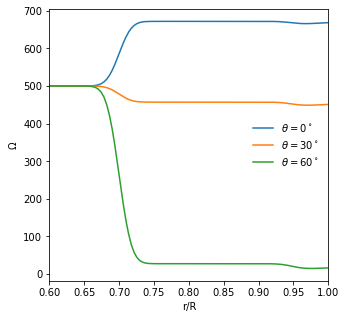

In [57]:
rr = np.linspace(0.0,1.0,256)

plt.figure(figsize=(5,5))
plt.plot(rr,Omega(rr,np.deg2rad(0.0)+np.pi/2.0),label=r"$\theta =   0^\circ$")
# plt.plot(rr,Omega(rr,np.deg2rad(10.0)),label=r"$\theta = 10^\circ$")
plt.plot(rr,Omega(rr,np.deg2rad(30.0)+np.pi/2.0),label=r"$\theta = 30^\circ$")
plt.plot(rr,Omega(rr,np.deg2rad(60.0)+np.pi/2.0),label=r"$\theta = 60^\circ$")
# plt.plot(rr,Omega(rr,np.deg2rad(90.0)),label=r"$\theta = 90^\circ$")
plt.xlabel("r/R")
plt.ylabel(r"$\Omega$")
plt.xlim([0.6,1.0])
plt.legend(frameon=False)

In [36]:
def OmegaPencil(r,theta):

    #     &hydro_run_pars
    #           kinematic_flow='spoke-like-NSSL', uphi_rbot=.7, uphi_rtop=.97
    #           uphi_step_width=.03, ampl_kinflow=5e4
    uphi_rbot = 0.7
    uphi_rtop = 1.0
    uphi_step_width = 0.05
    # uphi_step_width = 10.0 * np.mean(np.ediff1d(r))
    ampl_kinflow=1e6

    profx_kinflow1=+0.5*(1.+erf(((r-uphi_rbot)/uphi_step_width)))
    profx_kinflow2=+0.5*(1.-erf(((r-uphi_rtop)/uphi_step_width)))
    profx_kinflow3=+0.5*(1.+erf(((r-uphi_rtop)/uphi_step_width)))

    profx_kinflow2=(r-uphi_rbot)*profx_kinflow1*profx_kinflow2 # !(redefined)
    profy_kinflow1=-1.5*(5.0*np.cos(theta)**2-1.0)
    profy_kinflow2=-1.0*(4.0*np.cos(theta)**2-3.0)
    profy_kinflow3=-1.0
    profz_kinflow1=+1.0

    local_Omega = ampl_kinflow*profx_kinflow1*profy_kinflow1+ampl_kinflow*profx_kinflow2*profy_kinflow2+ampl_kinflow*profx_kinflow3*profy_kinflow3
        # Definition from Pencil code
        #   p%uu(:,1)=0.
        #   p%uu(:,2)=0.
        #   p%uu(:,3)=local_Omega*x(l1:l2)*sinth(m)
    if (theta != 0.0):
        return local_Omega*r*np.sin(theta) / (2.0 * np.pi) * 3600 + 500
    else:
        return local_Omega*r / (2.0 * np.pi) * 3600 + 500

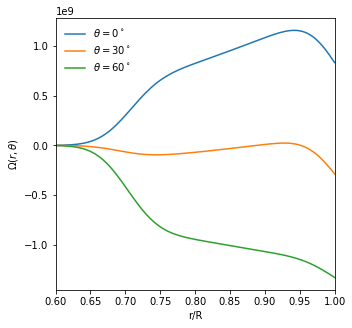

In [37]:
rr = np.linspace(0.0,1.0,256)

plt.figure(figsize=(5,5))
plt.plot(rr,OmegaPencil(rr,np.deg2rad(0.0001)+np.pi/2),label=r"$\theta =   0^\circ$")
# plt.plot(rr,OmegaPencil(rr,np.deg2rad(16.0)+np.pi/2),label=r"$\theta = 5^\circ$")
# plt.plot(rr,OmegaPencil(rr,np.deg2rad(10.0)),label=r"$\theta = 10^\circ$")
plt.plot(rr,OmegaPencil(rr,np.deg2rad(30.0)+np.pi/2),label=r"$\theta = 30^\circ$")
plt.plot(rr,OmegaPencil(rr,np.deg2rad(60.0)+np.pi/2),label=r"$\theta = 60^\circ$")
# plt.plot(rr,OmegaPencil(rr,np.deg2rad(70.0)+np.pi/2),label=r"$\theta = 70^\circ$")
plt.xlabel("r/R")
plt.ylabel(r"$\Omega(r,\theta)$")
plt.xlim([0.6,1.0])
plt.legend(frameon=False)

In [10]:
azimuths = np.radians(np.linspace(0, 360, 360))
zeniths = np.linspace(0.0, 1.0, 360)

r, theta = np.meshgrid(zeniths, azimuths) # r should == R

omega = Omega(r,theta) 


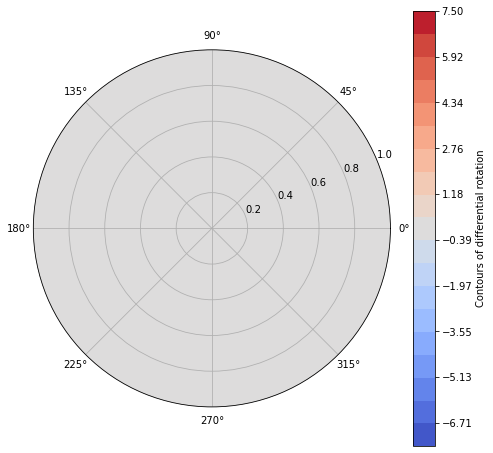

In [11]:
fig, ax = plt.subplots(subplot_kw=dict(projection='polar'),figsize=(8,8))

contour_levels = np.linspace(-7.5,7.5,20)
# contour_levels = np.linspace(0.1,omega.max(),64)


CS = ax.contourf(theta, r, omega, contour_levels,cmap=cm.coolwarm)

cbar = plt.colorbar(CS)
cbar.set_label(r"Contours of differential rotation")